# The sieve grid, P80 by interpolation and the oracle at x63

**Question:** How large is the error of reading a size from the engine's sieve grid by interpolation, how does it shrink with a finer grid, and does the engine agree with the closed-form law once the grid's top size is accounted for?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- build the square-root-of-two grid and check its ratio and its class mid-sizes;
- turn the class masses of a feed into a cumulative passing curve, and say how the normalisation works;
- read a size at a passing fraction and a passing fraction at a size, and state the interpolation rule of each reading;
- measure the interpolation error against an exact reference, and show it falls as the grid is refined;
- check the engine against the oracle at x63, correcting the oracle for the grid's top size.

## Setup

The two libraries of the set, numpy and matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The cell imports the grid and interpolation utilities of the engine (`model/crusher/sieve.py`, `feed.py`) and the oracle's closed-form law, under names that keep it apart from the engine's functions of the same name.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
import math

from pipeline.model.crusher.feed import make_feed
from pipeline.model.crusher.sieve import make_grid, mid_sizes, cumulative_passing, to_psd, size_at_passing, passing_at_size
from pipeline.oracles import rosin_rammler_passing as law_passing
from pipeline.oracles import rosin_rammler_size_at as law_size_at
from pipeline.oracles import rosin_rammler_x63_passing as law_at_x63
from pipeline.oracles import mass_closure
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The feed of the reference case S01, as in notebook 01. Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. File read: `data/derived/manifests/S01.json`, block `params`.

The cell reads the feed parameters.

In [2]:
# Read x63 and m of the reference feed
params = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"]
X63, M = params["feed_x63_mm"], params["feed_m"]
print(f"x63 = {X63} mm, m = {M}")

x63 = 90.0 mm, m = 1.2


## Method

**Step 1, the grid.** The engine's grid is the standard laboratory series: each edge is the previous one divided by $\sqrt 2$, starting at 256 mm, 29 edges for 28 classes. The mid-size of class $i$ is the geometric mean of its edges, $\sqrt{e_i e_{i+1}}$, the natural centre on a ratio scale. The cell builds the grid and checks that every consecutive ratio is $\sqrt 2$ and that every mid-size sits $2^{-1/4}$ below the upper edge.

In [3]:
# Build the grid and check its geometric structure
edges = make_grid(256, 28)
mids = mid_sizes(edges)
ratios = np.array(edges[:-1]) / np.array(edges[1:])
print("edges:", len(edges), "| classes:", len(mids))
print("ratio min and max:", ratios.min().round(12), ratios.max().round(12), "| sqrt(2) =", round(math.sqrt(2), 12))
print("mid / upper edge:", (np.array(mids) / np.array(edges[:-1])).round(6)[:3], "| 2^(-1/4) =", round(2 ** -0.25, 6))

edges: 29 | classes: 28
ratio min and max: 1.414213562373 1.414213562373 | sqrt(2) = 1.414213562373
mid / upper edge: [0.840896 0.840896 0.840896] | 2^(-1/4) = 0.840896


**Step 2, from class masses to a passing curve.** The mass of a class is the law's difference between its edges, and the engine turns the 28 masses into a cumulative curve in two moves. `to_psd` renormalises the masses to sum to 1, which is what makes the curve end at 100 percent at the top edge; `cumulative_passing` then accumulates from the finest class upward, so that the passing at an edge is the mass of all classes below it. The cell builds the S01 feed and shows both normalisations: the raw sum of the class masses, which is $R(256)$ because everything above the top edge is missing, and the renormalised one.

In [4]:
# Raw class masses of the law, their sum, and the renormalised feed the engine uses
raw = [law_passing(edges[i], X63, M) - law_passing(edges[i + 1], X63, M) for i in range(28)]
feed = to_psd(edges, raw)
print("sum of the raw masses:", round(sum(raw), 6), "| R(256) from the law:", round(law_passing(256, X63, M), 6))
print("sum after to_psd:", round(sum(feed.mass), 12), "| mass closure oracle:", mass_closure([1.0], list(feed.mass)))
same = make_feed(edges, X63, M)
print("make_feed gives the same masses:", np.allclose(same.mass, feed.mass, rtol=0, atol=1e-15))
print("passing at the top edge:", feed.passing[0], "| at the bottom edge:", feed.passing[-1])

sum of the raw masses: 0.969949 | R(256) from the law: 0.96998
sum after to_psd: 1.0 | mass closure oracle: 0.0
make_feed gives the same masses: True
passing at the top edge: 1.0 | at the bottom edge: 0.0


The raw masses sum to 0.96995, within 0.00003 of the law's $R(256)$ (the difference is the sliver finer than the grid's finest edge), and after `to_psd` they sum to 1: the engine's feed is the law conditioned on being finer than 256 mm. The figure draws the mass per class of this feed as bars on the grid, the form in which a sieve analysis is usually written down, with the geometric mid-sizes on the axis.

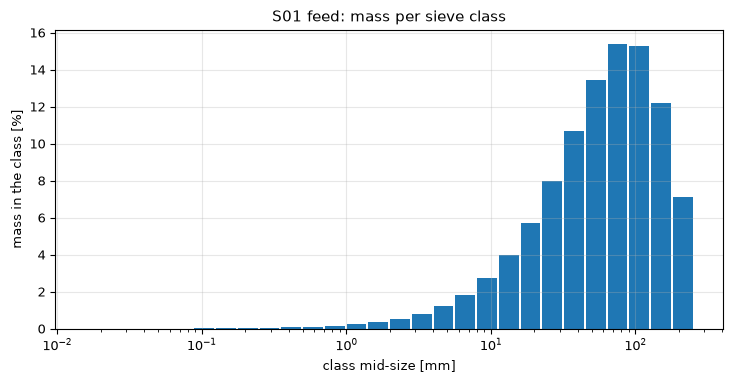

In [5]:
# Bar chart of the mass per class of the S01 feed against the class mid-size
fig, ax = plt.subplots()
widths = np.array(edges[:-1]) - np.array(edges[1:])
ax.bar(mids, np.array(feed.mass) * 100, width=widths * 0.9, align="center")
ax.set_xscale("log")
ax.set_xlabel("class mid-size [mm]")
ax.set_ylabel("mass in the class [%]")
ax.set_title("S01 feed: mass per sieve class")
fig.tight_layout()
plt.show()

The bars rise to a peak between 75 and 110 mm and fall on both sides, the shape of a Weibull density seen on a logarithmic axis. Because the classes are geometric, a bar's width on this axis is constant, so equal heights are equal masses. The figure shows where the feed's mass sits and not how fine the product will be; that comes from the breakage in topic 03.

**Step 3, the two readings.** The engine reads the curve in two directions. `size_at_passing` takes a fraction and returns a size: it finds the bracket of edges that contains the fraction and interpolates linearly in the logarithm of the size, $\ln x = \ln e_{lo} + t(\ln e_{hi} - \ln e_{lo})$ with $t$ the fractional position of the passing between the two edges' passing values. `passing_at_size` goes the other way, linear in the logarithm of the size. The pair is consistent by construction, and the cell verifies it: reading a size and then reading its passing gives back the fraction.

In [6]:
# Round trip: fraction to size to fraction, for several fractions
for p in (0.2, 0.5, 0.8, 0.95):
    x = size_at_passing(feed, p)
    print(f"p = {p:.2f} -> x = {x:8.3f} mm -> p = {passing_at_size(feed, x):.6f}")

p = 0.20 -> x =   24.786 mm -> p = 0.200000
p = 0.50 -> x =   63.944 mm -> p = 0.500000
p = 0.80 -> x =  126.033 mm -> p = 0.800000
p = 0.95 -> x =  200.613 mm -> p = 0.950000


**Step 4, the interpolation error.** Reading a size between two edges assumes the curve is a straight line in log size there, which the true curve is not. The error is therefore a property of the grid, and a finer grid should shrink it. To measure it we need an exact reference for the same truncated feed: the truncated law has $R_T(x) = R(x)/R(256)$, so its F80 solves $R(x) = 0.8\,R(256)$, which the oracle inverts directly, `law_size_at(0.8 * R(256), x63, m)`. The cell builds grids with ratios 2, $\sqrt2$, $2^{1/4}$ and $2^{1/8}$ (14, 28, 56 and 112 classes down from 256 mm) and compares each engine F80 with that reference.

In [7]:
# Interpolation error of F80 against the exact truncated law, for four grid ratios
top = law_passing(256, X63, M)
exact_f80 = law_size_at(0.8 * top, X63, M)
rows = []
for ratio, classes in ((2.0, 14), (math.sqrt(2), 28), (2 ** 0.25, 56), (2 ** 0.125, 112)):
    grid = make_grid(256, classes, ratio)
    f80 = size_at_passing(make_feed(grid, X63, M), 0.8)
    rows.append((ratio, classes, f80, (f80 - exact_f80) / exact_f80 * 100))
    print(f"ratio {ratio:.4f}  classes {classes:3d}  F80 {f80:8.3f} mm  error {rows[-1][3]:+.4f} %")
print("exact F80 of the truncated law:", round(exact_f80, 3), "mm")

ratio 2.0000  classes  14  F80  126.042 mm  error +0.1122 %
ratio 1.4142  classes  28  F80  126.033 mm  error +0.1055 %
ratio 1.1892  classes  56  F80  125.983 mm  error +0.0654 %
ratio 1.0905  classes 112  F80  125.943 mm  error +0.0337 %
exact F80 of the truncated law: 125.901 mm


From the square-root-of-two grid on, each halving of the log-spacing roughly halves the error (0.11, 0.07 and 0.03 percent), so the interpolation is first order in the grid step. The figure plots the error against the grid ratio on a logarithmic axis. The curve is not a straight line through zero because the true F80 also depends on where the edges fall relative to the 80 percent level; the trend, not each point, is what to read.

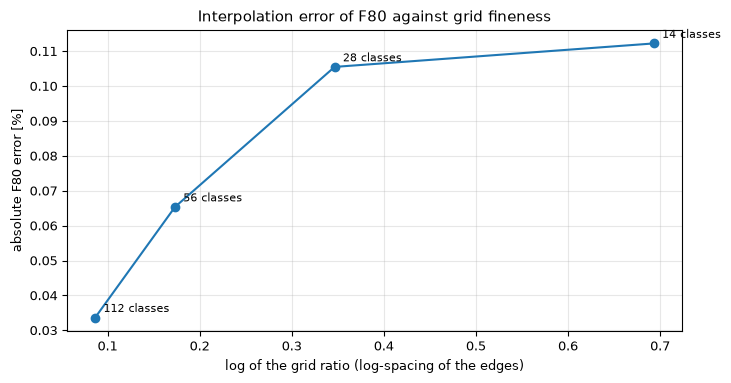

In [8]:
# Plot the F80 interpolation error against the logarithm of the grid ratio
fig, ax = plt.subplots()
ax.plot([math.log(r[0]) for r in rows], [abs(r[3]) for r in rows], "o-")
for ratio, classes, _, err in rows:
    ax.annotate(f"{classes} classes", (math.log(ratio), abs(err)), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("log of the grid ratio (log-spacing of the edges)")
ax.set_ylabel("absolute F80 error [%]")
ax.set_title("Interpolation error of F80 against grid fineness")
fig.tight_layout()
plt.show()

The error is at most 0.11 percent on the coarsest grid and 0.03 percent on the finest. The product's sizes are therefore read with a precision much better than the other uncertainties in the problem (the feed's own top size, the ore, the plant measurement), which is why the sqrt2 grid is adequate. A larger error would show up as a visible trend in this figure; it is a bound for a smooth feed, not for a bimodal feed whose steep part falls between two edges.

**Step 5, the oracle at x63.** The oracle states a fact about the law, not about the engine: $R(x_{63}) = 1 - 1/e = 0.632$ for every $m$. The engine's feed is the truncated law, so its passing at $x_{63}$ is $R(x_{63})/R(256)$, higher than 0.632 by the factor $1/R(256)$. Multiplying the engine's passing at $x_{63}$ by $R(256)$ should return the oracle's constant. The cell does it for six feeds of different $x_{63}$ and $m$ and prints the engine's raw value, the corrected value and the oracle's.

In [9]:
# Engine passing at x63, raw and corrected for the 256 mm top size, against the oracle's 1 - 1/e
cases = ((60, 0.9), (90, 1.2), (90, 2.0), (120, 1.5), (40, 0.7), (150, 2.5))
print("x63    m    engine raw   corrected   oracle")
for x63, m in cases:
    f = make_feed(edges, x63, m)
    raw_value = passing_at_size(f, x63)
    corrected = raw_value * law_passing(256, x63, m)
    print(f"{x63:4d} {m:5.1f} {raw_value:12.4f} {corrected:11.4f} {law_at_x63():9.4f}")

x63    m    engine raw   corrected   oracle
  60   0.9       0.6483      0.6321    0.6321
  90   1.2       0.6517      0.6322    0.6321
  90   2.0       0.6326      0.6324    0.6321
 120   1.5       0.6622      0.6328    0.6321
  40   0.7       0.6473      0.6307    0.6321
 150   2.5       0.6452      0.6308    0.6321


## Results

**Answer:** the interpolation error of F80 is 0.1055 percent on the engine's sqrt2 grid and falls to 0.0337 percent on a grid with four times as many classes per factor of two, first order in the step, so the engine reads sizes from its grid with an error far below the other uncertainties of the problem. Against the oracle, the engine's passing at $x_{63}$ is not 0.632 but 0.6517 for S01, since the grid drops 3.00 percent of the law's mass; multiplied by $R(256) = 0.9700$ it gives 0.6322, within 0.0001 of the oracle's $1 - 1/e = 0.6321$, and within 0.0014 for all six feeds tried (the remainder is interpolation).

The first figure shows the feed's class masses, and the second the error shrinking with the grid. A validator would conclude that the engine's size distribution is a faithful discretisation of the Rosin-Rammler law truncated at the top of the grid, and that the oracle agrees with it only after that truncation is accounted for. What the checks do not establish is that the Rosin-Rammler law describes a real crusher feed; that is an assumption of the product, which the real lane of topic 05 states as a documented one (m = 0.9).

## Summary

The grid is a geometric series, the masses are law differences renormalised to 1, and sizes are read by interpolation in log size, with an error that is first order in the grid step and about 0.1 percent at the engine's resolution. The oracle at x63 holds for the engine's feed once the 256 mm top size is accounted for. The next topic takes the size distribution through the crusher: breakage, classification and the Whiten solve.

## References

- Rosin, P., Rammler, E. (1933), The laws governing the fineness of powdered coal, Journal of the Institute of Fuel 7, 29-36. https://cir.nii.ac.jp/crid/1572543024341127296
- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193